In [ ]:
from pathlib import Path
import sys

# Localizar la raiz del repositorio desde Jupyter o terminal
RAIZ_REPO = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks").is_dir() and (p / "datos").is_dir()),
    None
)
if RAIZ_REPO is None:
    raise FileNotFoundError("Ejecuta desde el repositorio caso-itam")

sys.path.insert(0, str(RAIZ_REPO / "src"))


## Modelo de supervivencia del rezago de denuncia

Requiere `pandas`, `pyarrow`, `lifelines` (`autograd`), `scipy` y `matplotlib`

In [ ]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# El cuaderno vive en  Caso ITAM\EDA\ENVIPE
# Los datos viven en   Caso ITAM\Datos procesados
# Subimos dos niveles (ENVIPE -> EDA -> Caso ITAM) y entramos a "Datos procesados".
RAIZ = RAIZ_REPO
RUTA_DATOS   = RAIZ / "datos" / "procesados"
RUTA_SALIDAS = RAIZ / "resultados" / "modelo_supervivencia"
RUTA_SALIDAS.mkdir(exist_ok=True)       # la crea si no existe; si ya está, no hace nada

FECHA_CORTE = pd.Timestamp("2025-01-31")

# Verificamos ANTES de intentar leer. Si algo falla, el mensaje dice exactamente qué.
assert RUTA_DATOS.exists(), f"No existe la carpeta de datos: {RUTA_DATOS}"
print("Datos   :", RUTA_DATOS)
print("Salidas :", RUTA_SALIDAS)
print("\nParquets disponibles:")
for p in sorted(RUTA_DATOS.glob("*.parquet")):
    print(f"   {p.name:45s} {p.stat().st_size/1e6:8.1f} MB")

# pq.ParquetFile lee solo los metadatos (esquema y número de filas),
# no los datos. Es instantáneo aunque el archivo sea grande.
archivo_fgj = pq.ParquetFile(RUTA_DATOS / "fgj_carpetas.parquet")
print(f"\nFilas totales: {archivo_fgj.metadata.num_rows:,}")
print(f"Grupos de filas: {archivo_fgj.metadata.num_row_groups}")

In [ ]:
# Carga selectiva de fgj_carpetas

# Leemos solo las columnas que usa el modelo. Dejamos fuera
# latitud/longitud (no se usan), alcaldia_catalogo (99% vacía)
# y anio_* (los recalcularemos desde las fechas, que es más confiable).

columnas = ["fecha_inicio", "fecha_hecho", "delito", "categoria_delito",
            "competencia", "fiscalia", "alcaldia_hecho", "municipio_hecho"]

fgj = pd.read_parquet(RUTA_DATOS / "fgj_carpetas.parquet", columns=columnas)

# Truco de memoria: las columnas de texto con pocos valores distintos
# (delito, fiscalía, alcaldía…) se repiten millones de veces.
# El tipo "category" guarda cada valor distinto una sola vez y en cada
# fila solo un número entero que apunta a él. Ahorra mucha memoria y
# acelera los groupby. Las fechas las dejamos como texto: se parsean
# en la siguiente celda.
for col in ["delito", "categoria_delito", "competencia", "fiscalia",
            "alcaldia_hecho", "municipio_hecho"]:
    fgj[col] = fgj[col].astype("category")

print(f"Filas: {len(fgj):,}")
print(f"Memoria: {fgj.memory_usage(deep=True).sum()/1e6:,.0f} MB\n")

# Cuántos valores distintos y cuántos nulos tiene cada columna
resumen = pd.DataFrame({
    "valores_distintos": fgj.nunique(),
    "nulos": fgj.isna().sum(),
})
print(resumen)

# Un vistazo a los valores de las columnas que usaremos como filtro
print("\ncompetencia:")
print(fgj["competencia"].value_counts(dropna=False))
print("\nmunicipio_hecho (top 5):")
print(fgj["municipio_hecho"].value_counts(dropna=False).head())

Filas: 2,098,743
Memoria: 263 MB

                  valores_distintos    nulos
fecha_inicio                  56540        3
fecha_hecho                   32513      560
delito                          357        0
categoria_delito                 18        0
competencia                       3  1064018
fiscalia                        100        2
alcaldia_hecho                   17    24896
municipio_hecho                   1        0

competencia:
competencia
NaN                   1064018
FUERO COMUN           1000272
HECHO NO DELICTIVO      22096
INCOMPETENCIA           12357
Name: count, dtype: int64

municipio_hecho (top 5):
municipio_hecho
CDMX    2098743
Name: count, dtype: int64


In [ ]:
# Parseo de fechas

# Las fechas vienen en dos formatos: "AAAA-MM-DD" y "AAAA-MM-DD HH:MM:SS".
# Tomamos los primeros 10 caracteres de ambas: así los dos formatos
# quedan iguales, y además normalizamos a medianoche (la hora no es
# confiable, como ya sabíamos).

fgj = fgj.drop(columns="municipio_hecho")   # constante: siempre "CDMX"

# Guardamos cuántos registros traían hora, para documentarlo
trae_hora = fgj["fecha_hecho"].str.len() == 19

for col in ["fecha_hecho", "fecha_inicio"]:
    # format= le dice a pandas el formato exacto, y eso lo vuelve
    # mucho más rápido que dejarlo adivinar.
    # errors="coerce": lo que no se pueda leer queda como NaT
    # (el "nulo" de las fechas) en lugar de detener la celda.
    fgj[col] = pd.to_datetime(fgj[col].str[:10], format="%Y-%m-%d",
                              errors="coerce")

print("Registros cuya fecha_hecho traía hora:", f"{trae_hora.sum():,}")
print("Rango de esos registros (fecha del hecho):",
      fgj.loc[trae_hora, "fecha_hecho"].min().date(), "a",
      fgj.loc[trae_hora, "fecha_hecho"].max().date())

print("\nFechas que quedaron sin valor tras el parseo:")
print(fgj[["fecha_hecho", "fecha_inicio"]].isna().sum())

print("\nRangos:")
for col in ["fecha_hecho", "fecha_inicio"]:
    print(f"  {col:13s} {fgj[col].min().date()}  a  {fgj[col].max().date()}")

# Descartamos explícitamente lo que no tiene alguna de las dos fechas
n_antes = len(fgj)
fgj = fgj.dropna(subset=["fecha_hecho", "fecha_inicio"]).reset_index(drop=True)
print(f"\nDescartados por fecha faltante: {n_antes - len(fgj):,}")
print(f"Quedan: {len(fgj):,}")

Registros cuya fecha_hecho traía hora: 53,555
Rango de esos registros (fecha del hecho): 1968-01-30 a 2025-01-31

Fechas que quedaron sin valor tras el parseo:
fecha_hecho     560
fecha_inicio      3
dtype: int64

Rangos:
  fecha_hecho   1906-06-02  a  2025-01-31
  fecha_inicio  2016-01-01  a  2025-01-31

Descartados por fecha faltante: 563
Quedan: 2,098,180


### Decisiones

- Rezagos negativos (110). La mitad son de −1 o −2 días, y el peor es de −362. Una carpeta no puede iniciarse antes del hecho, así que son errores de captura: lo más probable es que las fechas estén intercambiadas o mal tecleadas. Se descartan. Son 0.005% de la base, y solo 13 caen en los años 2020 a 2024. Imputarles un valor sería inventar datos sin ganar nada.

- Rezagos de más de cinco años (12,530). Aquí la decisión casi se toma sola. Un hecho de 2020 a 2024 con corte en enero de 2025 puede tener como máximo unos cinco años y un mes de rezago, así que solo 7 de esos casos caen en el universo del modelo, y son legítimos: hechos de enero de 2020 denunciados en enero de 2025. Los demás son hechos anteriores a 2011, algunos verosímiles (delitos sexuales denunciados décadas después) y otros claramente erróneos (el de 1906). No se borran: se marcan con una bandera. El filtro de años del núcleo los saca del modelo de forma natural, y en el panorama descriptivo los reportas aparte en lugar de mezclarlos con el resto.

In [ ]:
# Rezago, ventana de observación y limpieza

# Restar dos fechas da un "timedelta" (una duración).
# .dt.days lo convierte a número entero de días.
fgj["rezago"]      = (fgj["fecha_inicio"] - fgj["fecha_hecho"]).dt.days
fgj["ventana_max"] = (FECHA_CORTE - fgj["fecha_hecho"]).dt.days

# Variables de calendario del hecho (se usan como covariables y filtros)
fgj["anio_hecho"] = fgj["fecha_hecho"].dt.year.astype("int16")
fgj["mes_hecho"]  = fgj["fecha_hecho"].dt.month.astype("int8")

print("Rezago antes de limpiar (días):")
print(fgj["rezago"].describe(percentiles=[.5, .9, .99]).round(1))

# --- Decisión 1: negativos → se descartan (errores de captura) ---
negativos = fgj["rezago"] < 0
print(f"\nRezagos negativos: {negativos.sum():,}")
print("   de ellos, con hecho en 2020-2024:",
      (negativos & fgj["anio_hecho"].between(2020, 2024)).sum())
fgj = fgj.loc[~negativos].reset_index(drop=True)

# --- Decisión 2: más de 5 años → se marcan, no se borran ---
CINCO_ANIOS = 5 * 365
fgj["rezago_mayor_5a"] = fgj["rezago"] > CINCO_ANIOS
print(f"\nRezagos de más de 5 años (marcados): {fgj['rezago_mayor_5a'].sum():,}")
print("   de ellos, con hecho en 2020-2024:",
      (fgj["rezago_mayor_5a"] & fgj["anio_hecho"].between(2020, 2024)).sum())

# Verificación de coherencia: el rezago nunca puede exceder la ventana
# (la carpeta tuvo que abrirse antes del corte). Si esto no da 0,
# hay un problema en las fechas.
print("\nCasos con rezago > ventana_max (debe ser 0):",
      (fgj["rezago"] > fgj["ventana_max"]).sum())

print(f"\nQuedan: {len(fgj):,}")

Rezago antes de limpiar (días):
count    2098180.0
mean          61.4
std          418.3
min         -362.0
50%            1.0
90%           71.0
99%         1170.0
max        40179.0
Name: rezago, dtype: float64

Rezagos negativos: 110
   de ellos, con hecho en 2020-2024: 13

Rezagos de más de 5 años (marcados): 12,530
   de ellos, con hecho en 2020-2024: 7

Casos con rezago > ventana_max (debe ser 0): 0

Quedan: 2,098,070


### Covariables

- Tipo de delito: uso decision_final de la tabla v3, no delito_envipe. Coinciden salvo en un caso: TENTATIVA DE VIOLACION está asignada a 13 (hostigamiento y abuso) en tu decisión final. Quedan seis grupos.
- Canal digital: fiscalia == "AGENCIA DE DENUNCIA DIGITAL". Verifiqué que es el único valor con “DIGITAL”.
- Violencia: el texto “CON VIOLENCIA” solo existe en robos. Amenazas, lesiones y delitos sexuales no traen la etiqueta. La codifico como 1/0 y, como el tipo de delito va en el modelo, el coeficiente se interpreta como el efecto de la violencia dentro de los robos. 

In [ ]:
# Universo del núcleo y covariables

import unicodedata

# --- 1. Tabla de correspondencia: qué delitos son núcleo y a qué grupo van ---
corr = pd.read_csv(RUTA_DATOS / "correspondencia_bpcod_fgj_v3.csv",
                   dtype=str, encoding="utf-8-sig")   # utf-8-sig quita el BOM del inicio
corr_nucleo = corr.loc[corr["v_nucleo"] == "True", ["delito", "decision_final"]]

ETIQUETAS_TIPO = {
    "04": "Robo a casa habitación",
    "05": "Robo en calle o transporte",
    "10": "Amenazas",
    "11": "Lesiones",
    "13": "Hostigamiento o abuso sexual",
    "14": "Violación",
}
# Diccionario delito -> grupo. .map() lo aplica fila por fila de forma
# vectorizada; lo que no esté en el diccionario queda nulo (= fuera del núcleo).
mapa_tipo = dict(zip(corr_nucleo["delito"],
                     corr_nucleo["decision_final"].map(ETIQUETAS_TIPO)))
fgj["tipo_delito"] = fgj["delito"].astype(str).map(mapa_tipo).astype("category")
fgj["en_catalogo_nucleo"] = fgj["tipo_delito"].notna()

# --- 2. Clave de alcaldía, para pegar con el maestro por cve_mun ---
maestro = pd.read_parquet(RUTA_DATOS / "maestro_alcaldia.parquet")

def normalizar(texto):
    """Mayúsculas y sin acentos: 'Álvaro Obregón' -> 'ALVARO OBREGON'."""
    sin_acentos = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sin_acentos.upper().strip()

mapa_cve = {normalizar(n): c for n, c in
            maestro[["nombre", "cve_mun"]].drop_duplicates().itertuples(index=False)}
fgj["cve_mun"] = fgj["alcaldia_hecho"].astype(str).map(mapa_cve)  # nulo si no es alcaldía válida

# Verificación: las 16 alcaldías deben encontrar su clave
sin_clave = set(fgj["alcaldia_hecho"].dropna().unique()) - {k for k in mapa_cve}
print("Valores de alcaldia_hecho sin clave (solo debe salir la indeterminada):", sin_clave)

# --- 3. Covariables ---
fgj["digital"]       = (fgj["fiscalia"] == "AGENCIA DE DENUNCIA DIGITAL").astype("int8")
fgj["con_violencia"] = fgj["delito"].astype(str).str.contains("CON VIOLENCIA").astype("int8")

# --- 4. Universo del modelo: las cuatro condiciones ---
competencia_excluida = fgj["competencia"].isin(["HECHO NO DELICTIVO", "INCOMPETENCIA"])
fgj["en_nucleo"] = (fgj["en_catalogo_nucleo"]
                    & ~competencia_excluida          # los nulos pasan: isin() da False en nulos
                    & fgj["cve_mun"].notna()
                    & fgj["anio_hecho"].between(2020, 2024))

print(f"\nCarpetas en el universo del núcleo: {fgj['en_nucleo'].sum():,}")

# --- 5. Cotejo contra C_nucleo del día 4 (no se modifica, solo se compara) ---
conteo_hoy = (fgj[fgj["en_nucleo"]]
              .groupby(["cve_mun", "anio_hecho"]).size()
              .rename("C_hoy").reset_index()
              .rename(columns={"anio_hecho": "anio_ref"}))
cotejo = maestro[["cve_mun", "anio_ref", "C_nucleo"]].merge(conteo_hoy, on=["cve_mun", "anio_ref"])
cotejo["dif"] = cotejo["C_hoy"] - cotejo["C_nucleo"]

print("\nCotejo por año contra el maestro (día 4):")
print(cotejo.groupby("anio_ref")[["C_nucleo", "C_hoy", "dif"]].sum())
print("\nCeldas alcaldía-año con diferencia:")
print(cotejo[cotejo["dif"] != 0])

# --- 6. Panorama rápido de las covariables dentro del núcleo ---
nuc = fgj[fgj["en_nucleo"]]
print("\nProporción digital por año del hecho (núcleo):")
print(nuc.groupby("anio_hecho")["digital"].mean().round(3))
print("\nCarpetas por tipo de delito (núcleo):")
print(nuc["tipo_delito"].value_counts())

Valores de alcaldia_hecho sin clave (solo debe salir la indeterminada): {'CDMX (indeterminada)'}

Carpetas en el universo del núcleo: 259,954

Cotejo por año contra el maestro (día 4):
          C_nucleo  C_hoy  dif
anio_ref                      
2020         49578  49578    0
2021         54117  54117    0
2022         55418  55417   -1
2023         51778  51778    0
2024         49064  49064    0

Celdas alcaldía-año con diferencia:
   cve_mun  anio_ref  C_nucleo  C_hoy  dif
47     011      2022      1864   1863   -1

Proporción digital por año del hecho (núcleo):
anio_hecho
2020    0.028
2021    0.047
2022    0.068
2023    0.059
2024    0.044
Name: digital, dtype: float64

Carpetas por tipo de delito (núcleo):
tipo_delito
Robo en calle o transporte      94694
Amenazas                        89323
Hostigamiento o abuso sexual    25630
Lesiones                        23087
Robo a casa habitación          17689
Violación                        9531
Name: count, dtype: int64


**Hallazgo 1: el canal digital solo existe en un tipo de delito**

El canal digital de la FGJ es para delitos patrimoniales sin violencia: fraude, robo de autopartes, robo de objetos. Dentro de tu núcleo, prácticamente solo lo usa el robo en calle o transporte. Esto tiene dos consecuencias:

1. En el modelo, el coeficiente de digital se identifica solo con ese tipo de robo. Hay que interpretarlo así, igual que la violencia, que solo existe en robos.
2. La proporción digital sobre todo el núcleo mezclaría dos cosas: el uso del canal y la composición de delitos de cada alcaldía. Una alcaldía con muchas amenazas saldría “poco digital” aunque sus robos se denuncien mucho en línea. Propongo calcularla sobre el robo en calle o transporte.

**Hallazgo 2: el 36% de los rezagos vale cero**

Los modelos de tiempo de falla acelerado trabajan con el logaritmo del tiempo, y el log de cero no existe. El parche habitual es sumar medio día. Pero hay una solución más correcta que además es igual de sencilla: censura por intervalos. Las fechas vienen en días, así que un rezago de 0 significa que la carpeta se abrió en algún momento entre 0 y 1 días después del hecho; uno de 3, entre 3 y 4 días. Le pasamos al modelo ese intervalo en vez de un número exacto, y los casos que superan 120 días quedan como “más de 120”, con intervalo [120, ∞).

lifelines lo hace con fit_interval_censoring. Ya lo probé: los 68 mil casos de enero a marzo ajustan en unos 3 segundos con log-logística y unos 6 con log-normal. No hay riesgo de que tarde.

Un detalle que hace funcionar el diseño: un hecho del 31 de marzo de 2024 tuvo 306 días de ventana antes del corte, más que los 120 del truncamiento. Todos los casos de la versión garantizada tienen la ventana completa.

In [ ]:
# Entregable 1 y datos de la versión garantizada

import numpy as np

# --- Entregable 1: base limpia completa (2016-2025) con banderas ---
# Guardamos todo, no solo el núcleo, para que el panorama descriptivo
# salga de este mismo archivo. La bandera en_nucleo marca el universo del modelo.
cols_guardar = ["fecha_hecho", "fecha_inicio", "anio_hecho", "mes_hecho",
                "delito", "categoria_delito", "tipo_delito", "competencia",
                "fiscalia", "alcaldia_hecho", "cve_mun",
                "rezago", "ventana_max", "rezago_mayor_5a",
                "digital", "con_violencia", "en_catalogo_nucleo", "en_nucleo"]
fgj[cols_guardar].to_parquet(RUTA_SALIDAS / "fgj_rezago.parquet", index=False)
print("Guardado fgj_rezago.parquet:", f"{len(fgj):,} filas")

# --- Datos de la versión garantizada ---
TRUNC = 120
garant = fgj.loc[fgj["en_nucleo"] & (fgj["mes_hecho"] <= 3)].copy()

# Censura por intervalos: el evento ocurrió entre L y U días.
#   rezago < 120  -> [rezago, rezago + 1)
#   rezago >= 120 -> [120, infinito)   (censurado: "más de 120 días")
garant["L"] = garant["rezago"].clip(upper=TRUNC).astype(float)
garant["U"] = np.where(garant["rezago"] >= TRUNC, np.inf, garant["rezago"] + 1.0)
# lifelines trabaja con log(tiempo); un límite inferior exactamente 0 da
# problemas numéricos, así que lo movemos a un valor minúsculo.
garant["L"] = garant["L"].replace(0, 1e-6)

print(f"\nCasos enero-marzo 2020-2024: {len(garant):,}")
print(f"Censurados (> {TRUNC} días): {np.isinf(garant['U']).mean():.1%}")
print(f"Ventana mínima disponible: {garant['ventana_max'].min()} días (debe ser > {TRUNC})")

# --- Matriz de diseño con categorías de referencia elegidas a mano ---
# pd.get_dummies crea una columna 0/1 por categoría. Quitamos a mano la
# de referencia para que cada coeficiente se lea como "comparado con…".
REF_TIPO, REF_ALC, REF_ANIO = "Robo en calle o transporte", "015", 2020   # 015 = Cuauhtémoc

def matriz_diseno(df):
    X = pd.get_dummies(df[["tipo_delito", "cve_mun", "anio_hecho"]].astype(str),
                       prefix=["tipo", "alc", "anio"], dtype=float)
    X = X.drop(columns=[f"tipo_{REF_TIPO}", f"alc_{REF_ALC}", f"anio_{REF_ANIO}"])
    X["digital"] = df["digital"].astype(float)
    X["con_violencia"] = df["con_violencia"].astype(float)
    return X

X_garant = matriz_diseno(garant)
X_garant[["L", "U"]] = garant[["L", "U"]].values
print(f"\nCovariables: {X_garant.shape[1] - 2}")
print("Referencias: tipo =", REF_TIPO, "| alcaldía = Cuauhtémoc | año = 2020")

Guardado fgj_rezago.parquet: 2,098,070 filas

Casos enero-marzo 2020-2024: 67,914
Censurados (> 120 días): 5.1%
Ventana mínima disponible: 306 días (debe ser > 120)

Covariables: 26
Referencias: tipo = Robo en calle o transporte | alcaldía = Cuauhtémoc | año = 2020


Elegí Cuauhtémoc como alcaldía de referencia porque es la de más carpetas y da comparaciones estables.

In [ ]:
# Versión garantizada: log-logística vs log-normal

from lifelines import LogLogisticAFTFitter, LogNormalAFTFitter
import time

modelos_garant = {}
for nombre, Clase in [("log-logística", LogLogisticAFTFitter),
                      ("log-normal",    LogNormalAFTFitter)]:
    t0 = time.time()
    modelo = Clase()
    # fit_interval_censoring: cada caso es un intervalo [L, U) en lugar de un tiempo exacto
    modelo.fit_interval_censoring(X_garant, lower_bound_col="L", upper_bound_col="U")
    modelos_garant[nombre] = modelo
    print(f"{nombre:14s}  AIC = {modelo.AIC_:,.1f}   ({time.time()-t0:.1f} s)")

mejor = min(modelos_garant, key=lambda k: modelos_garant[k].AIC_)
print(f"\nMenor AIC: {mejor}")

# --- Tabla de razones de tiempo ---
# El summary de lifelines tiene un índice de dos niveles: (parámetro, covariable).
# El parámetro de ubicación (alpha_ en log-logística, mu_ en log-normal) es el
# que lleva las covariables; el otro (beta_ / sigma_) es la forma de la curva.
nombres_alc = dict(zip(maestro["cve_mun"], maestro["nombre"]))

def tabla_razones(modelo):
    param_ubic = modelo.summary.index.get_level_values(0)[0]   # alpha_ o mu_
    s = modelo.summary.loc[param_ubic]
    s = s.drop(index="Intercept")
    t = pd.DataFrame({
        "razon_tiempo": s["exp(coef)"],
        "ic95_inf":     s["exp(coef) lower 95%"],
        "ic95_sup":     s["exp(coef) upper 95%"],
        "p":            s["p"],
    })
    # Etiquetas legibles: "alc_007" -> "Alcaldía: Iztapalapa", etc.
    def etiqueta(c):
        if c.startswith("alc_"):  return "Alcaldía: " + nombres_alc[c[4:]]
        if c.startswith("tipo_"): return "Tipo: " + c[5:]
        if c.startswith("anio_"): return "Año: " + c[5:]
        return {"digital": "Canal digital", "con_violencia": "Con violencia (robos)"}[c]
    t.index = [etiqueta(c) for c in t.index]
    return t

tablas = {k: tabla_razones(m) for k, m in modelos_garant.items()}

pd.set_option("display.float_format", "{:.3f}".format)
print(f"\nRazones de tiempo — {mejor}:")
print(tablas[mejor])

# Comparación rápida entre familias: ¿cuentan la misma historia?
comp = pd.DataFrame({k: v["razon_tiempo"] for k, v in tablas.items()})
print("\nCorrelación entre las razones de las dos familias:",
      f"{np.corrcoef(np.log(comp.iloc[:,0]), np.log(comp.iloc[:,1]))[0,1]:.3f}")

log-logística   AIC = 339,645.8   (5.9 s)
log-normal      AIC = 340,994.4   (12.5 s)

Menor AIC: log-logística

Razones de tiempo — log-logística:
                                    razon_tiempo  ic95_inf  ic95_sup     p
Alcaldía: Azcapotzalco                     0.975     0.893     1.066 0.579
Alcaldía: Coyoacán                         1.066     0.983     1.156 0.123
Alcaldía: Cuajimalpa de Morelos            1.593     1.365     1.859 0.000
Alcaldía: Gustavo A. Madero                1.166     1.087     1.250 0.000
Alcaldía: Iztacalco                        1.014     0.929     1.107 0.757
Alcaldía: Iztapalapa                       1.245     1.171     1.325 0.000
Alcaldía: La Magdalena Contreras           0.841     0.740     0.955 0.008
Alcaldía: Milpa Alta                       1.074     0.905     1.275 0.413
Alcaldía: Álvaro Obregón                   1.219     1.130     1.314 0.000
Alcaldía: Tláhuac                          1.060     0.960     1.171 0.248
Alcaldía: Tlalpan           

**Robustez**
Gana la log-logística por unos 1,350 puntos de AIC, una diferencia decisiva. Pero la correlación de 0.997 entre las razones de las dos familias dice que la elección no cambia la historia

Comparando siempre contra un robo en calle o transporte, sin violencia, en Cuauhtémoc, en 2020 y por canal presencial:

- Tipo de delito. Es el efecto más grande. Una violación tarda 3.7 veces más en convertirse en carpeta; el hostigamiento o abuso sexual, 2.7 veces más; las amenazas, 1.9 veces. Las lesiones son 18% más rápidas, probablemente porque muchas llegan por hospital o patrulla y no por iniciativa de la víctima. Esto es consistente con lo que se sabe de la denuncia de delitos sexuales: estigma, dependencia del agresor, revictimización.
- Violencia. Un robo con violencia llega a carpeta en 37% menos tiempo (razón 0.63). La gravedad acelera la decisión de denunciar.
- Alcaldía. Xochimilco (1.61) y Cuajimalpa (1.59) son 60% más lentas que Cuauhtémoc; Tlalpan, Iztapalapa y Álvaro Obregón, alrededor de 25%. Magdalena Contreras es la única claramente más rápida (0.84). Varias de las lentas son periféricas, así que en el día 9 vale la pena ver si esto se alinea con la distancia a sedes del ministerio público que ya tienes en el maestro.
- Año. De 2021 en adelante todo es 15–27% más lento que 2020. La explicación más probable es la pandemia: en 2020 se denunció menos, y lo que se denunció fue lo urgente. Es un efecto de composición, no de truncamiento, porque el diseño iguala las ventanas.

**El canal digital**: 1.93, no 0.1. Denunciar en línea casi duplica el tiempo hasta la carpeta. No es un error, y hay dos lecturas posibles que estos datos no permiten separar:

- Selección: quien denuncia en línea es quien no tenía urgencia. Se dio cuenta después, o necesita la carpeta para la aseguradora o para bloquear el teléfono.
- Procesamiento: en el canal digital, fecha_inicio puede ser la fecha en que el ministerio público valida la denuncia, no la fecha en que el ciudadano la envió. Eso agrega días de trámite.

La segunda lectura conecta directamente con k: sería tiempo institucional, no ciudadano. Asociación, no efecto causal, con dos mecanismos candidatos. Este coeficiente se identifica solo con el robo en calle o transporte.

### Verificación de supuestos:

#### Residuales de Cox-Snell

Si el modelo es correcto, H(t) evaluado en el tiempo de cada caso se distribuye como una exponencial con media 1. Se verifica graficando el riesgo acumulado de esos residuales contra la recta de 45°.

La prueba de riesgos proporcionales no aplica, porque la log-logística no es un modelo de riesgos proporcionales. Su supuesto equivalente es el de momios proporcionales: el logaritmo de los momios de supervivencia debe ser lineal en log(t), con rectas paralelas entre grupos. 

Parámetro de forma β = 0.816

Residual   H empírico   (ideal = residual)
   0.25       0.159
   0.50       0.582
   1.00       1.083
   2.00       1.930
   3.00       2.789


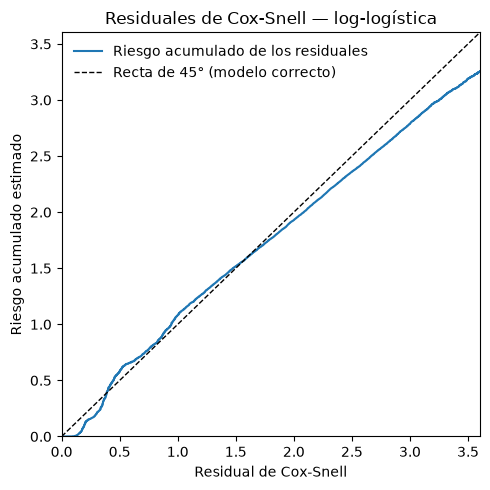

In [ ]:
# Verificación 1: residuales de Cox-Snell

import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

modelo_ll = modelos_garant["log-logística"]

# En la log-logística, S(t) = 1 / (1 + (t/α)^β).
#   α (escala) depende de las covariables de cada caso y es justo su mediana,
#     así que predict_median nos la da sin hacer álgebra a mano.
#   β (forma) es común a todos los casos.
alpha_i = modelo_ll.predict_median(X_garant).values.ravel()
beta    = np.exp(modelo_ll.params_.loc[("beta_", "Intercept")])
print(f"Parámetro de forma β = {beta:.3f}")

def riesgo_acumulado(t):
    """H(t) = −log S(t) = log(1 + (t/α)^β), caso por caso."""
    return np.log1p((t / alpha_i) ** beta)

# Residual de cada caso: un intervalo [H(L), H(U)]
r_inf = riesgo_acumulado(X_garant["L"].values)
r_sup = riesgo_acumulado(X_garant["U"].values)     # H(∞) = ∞ para los censurados
censurado = np.isinf(r_sup)

# Punto medio para los casos observados; los censurados se quedan en H(120)
# y entran como censura por la derecha.
r_medio = np.where(censurado, r_inf, (r_inf + r_sup) / 2)

# Si el modelo es correcto, los residuales son exponenciales con media 1,
# así que su riesgo acumulado estimado (−log de Kaplan-Meier) debe seguir y = x.
km_res = KaplanMeierFitter().fit(r_medio, event_observed=~censurado)
H_emp  = -np.log(km_res.survival_function_.iloc[:, 0])

# Valores puntuales para reportar
print("\nResidual   H empírico   (ideal = residual)")
for q in [0.25, 0.5, 1, 2, 3]:
    print(f"   {q:4.2f}       {-np.log(km_res.predict(q)):.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.step(H_emp.index, H_emp.values, where="post", lw=1.5, label="Riesgo acumulado de los residuales")
lim = min(H_emp.replace(np.inf, np.nan).max(), 4)
ax.plot([0, lim], [0, lim], "k--", lw=1, label="Recta de 45° (modelo correcto)")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Residual de Cox-Snell"); ax.set_ylabel("Riesgo acumulado estimado")
ax.set_title("Residuales de Cox-Snell — log-logística")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RUTA_SALIDAS / "diag_cox_snell.png", dpi=300)
plt.show()

Hasta un residual de 1.5 la curva sigue la recta, con el bache esperado al inicio por los ceros. Ese tramo cubre aproximadamente al 78% de los casos.

De 2 en adelante la curva queda por debajo de la recta: en 3, el riesgo empírico es 2.79 contra 3 ideal, unos 7% abajo. Que quede debajo significa que sobreviven más casos a residuales altos de lo que el modelo predice. Dicho en llano: los rezagos largos son más frecuentes de lo que la log-logística cree, así que la cola real es más pesada que la del modelo.

Con 68 mil casos la curva empírica es muy precisa, así que esta desviación es real y no ruido, aunque sea moderada. Y apunta a algo concreto: algún grupo tiene una cola más larga que los demás, y un modelo con una sola forma para todos no puede reproducirlo.

Esto importa para el factor de completitud. Si el modelo subestima la cola, subestima cuántas denuncias de diciembre de 2024 faltan por llegar, y el factor de corrección saldría corto. Vale la pena arreglarlo antes de llegar ahí.

**β = 0.816**

En la log-logística, cuando β ≤ 1 el riesgo es decreciente desde el primer día. En llano: la probabilidad de que se abra la carpeta es máxima justo después del delito y cae día con día. Si no se denuncia pronto, cada día que pasa es menos probable que se denuncie. Esa es una frase para el escrito, y conecta con d: la ventana para captar la denuncia es corta.

*Nota posterior:* al permitir β por tipo de delito (celdas siguientes), β queda cerca de 1 para robos y lesiones y cerca de 0.53 para delitos sexuales. El riesgo claramente decreciente es una característica de los delitos sexuales, no de todos los tipos; en el escrito se reporta así.

#### Supuesto de momios proporcionales

La log-logística supone que log[S(t) / (1 − S(t))] es una recta en log(t), con la misma pendiente para todos los grupos: rectas paralelas. Lo verificamos de forma no paramétrica: Kaplan-Meier por tipo de delito, transformado a esa escala.

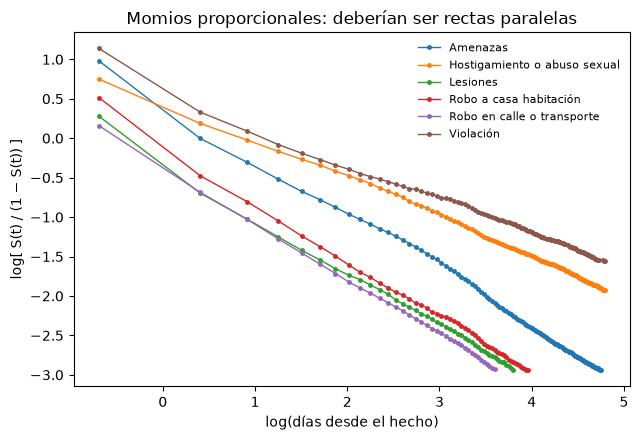

Pendiente que impone el modelo: −β = -0.816

Pendiente empírica por tipo:
Amenazas                       -0.728
Robo a casa habitación         -0.710
Robo en calle o transporte     -0.701
Lesiones                       -0.675
Hostigamiento o abuso sexual   -0.502
Violación                      -0.439
dtype: float64


In [ ]:
# Verificación 2: momios proporcionales por tipo de delito

# Kaplan-Meier no asume ninguna forma: es la curva "real" de los datos.
# Si la log-logística es correcta, al graficar log(S/(1−S)) contra log(t)
# cada tipo debe dar una recta, y todas deben ser paralelas (pendiente −β).

# Tiempo para Kaplan-Meier: punto medio del día; censurados en 120
garant["t_km"]    = np.minimum(garant["rezago"], TRUNC) + 0.5
garant["evento"]  = garant["rezago"] < TRUNC

fig, ax = plt.subplots(figsize=(6.5, 4.5))
pendientes = {}
for tipo, sub in garant.groupby("tipo_delito", observed=True):
    km = KaplanMeierFitter().fit(sub["t_km"], sub["evento"])
    S = km.survival_function_.iloc[:, 0]
    S = S[(S > 0.05) & (S < 0.95)]          # los extremos son inestables en esta escala
    log_t     = np.log(S.index.values)
    log_momio = np.log(S / (1 - S)).values
    ax.plot(log_t, log_momio, marker="o", ms=2.5, lw=1, label=tipo)
    # Pendiente de la recta ajustada: np.polyfit(x, y, 1) devuelve [pendiente, ordenada]
    pendientes[tipo] = np.polyfit(log_t, log_momio, 1)[0]

ax.set_xlabel("log(días desde el hecho)")
ax.set_ylabel("log[ S(t) / (1 − S(t)) ]")
ax.set_title("Momios proporcionales: deberían ser rectas paralelas")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_SALIDAS / "diag_momios_proporcionales.png", dpi=300)
plt.show()

print(f"Pendiente que impone el modelo: −β = {-beta:.3f}\n")
print("Pendiente empírica por tipo:")
print(pd.Series(pendientes).round(3).sort_values())

Las seis curvas son prácticamente rectas. Dentro de cada tipo de delito, la familia log-logística es adecuada. El problema no es la forma de la distribución, sino que no todos los tipos comparten la misma pendiente. (El primer tramo, más empinado, es el día cero otra vez.)

El problema: robos, amenazas y lesiones son casi paralelos, con pendientes de −0.68 a −0.73. Hostigamiento (−0.50) y violación (−0.44) son claramente más planos. En llano: la denuncia de delitos sexuales no solo es más lenta, también es más dispersa. Muchas víctimas denuncian pronto, pero una fracción importante tarda meses o años. Eso es sustantivo, no un detalle técnico.

In [ ]:
# Modelo principal: log-logística con forma β por tipo

# ancillary= le dice a lifelines qué covariables entran en el parámetro de
# FORMA (β), además de las que ya entran en la escala (α). Así cada tipo de
# delito tiene su propia pendiente: justo lo que la celda 9 pidió.
cols_tipo = [c for c in X_garant.columns if c.startswith("tipo_")]

t0 = time.time()
modelo_principal = LogLogisticAFTFitter()
modelo_principal.fit_interval_censoring(X_garant, lower_bound_col="L",
                                        upper_bound_col="U",
                                        ancillary=X_garant[cols_tipo])
print(f"Ajuste: {time.time()-t0:.1f} s")
print(f"AIC forma común : {modelo_ll.AIC_:,.1f}")
print(f"AIC forma por tipo: {modelo_principal.AIC_:,.1f}")
print(f"Mejora: {modelo_ll.AIC_ - modelo_principal.AIC_:,.1f} puntos")

# --- β por tipo de delito ---
coef_beta = modelo_principal.params_.loc["beta_"]
beta_tipo = {REF_TIPO: np.exp(coef_beta["Intercept"])}
for c in cols_tipo:
    beta_tipo[c[5:]] = np.exp(coef_beta["Intercept"] + coef_beta[c])
print("\nForma β por tipo (β < 1: riesgo decreciente; más chico = más disperso):")
print(pd.Series(beta_tipo).round(3).sort_values())

# --- Cox-Snell otra vez, ahora con β propio de cada caso ---
alpha_i = modelo_principal.predict_median(X_garant).values.ravel()
beta_i  = np.exp(coef_beta["Intercept"]
                 + (X_garant[cols_tipo] * coef_beta[cols_tipo]).sum(axis=1)).values
H = lambda t: np.log1p((t / alpha_i) ** beta_i)
r_inf, r_sup = H(X_garant["L"].values), H(X_garant["U"].values)
cens = np.isinf(r_sup)
km_res2 = KaplanMeierFitter().fit(np.where(cens, r_inf, (r_inf + r_sup) / 2), ~cens)
print("\nCox-Snell   forma común   forma por tipo   (ideal)")
for q in [0.25, 0.5, 1, 2, 3]:
    print(f"   {q:4.2f}       {-np.log(km_res.predict(q)):.3f}          "
          f"{-np.log(km_res2.predict(q)):.3f}          {q:.2f}")

# --- Tabla de resultados (entregable 4) ---
tabla_principal = tabla_razones(modelo_principal)
tabla_comun     = tablas["log-logística"]

def en_llano(rt):
    """Convierte una razón de tiempo en una frase para el jurado."""
    if rt >= 1.5:  return f"la mediana se multiplica por {rt:.1f}"
    if rt >= 1:    return f"la mediana es {100*(rt-1):.0f}% más larga"
    return f"la mediana es {100*(1-rt):.0f}% más corta"

tabla_final = tabla_principal.copy()
tabla_final["lectura"] = tabla_final["razon_tiempo"].apply(en_llano)
tabla_final["significativo"] = np.where(tabla_final["p"] < 0.05, "sí", "no")
tabla_final["razon_forma_comun"] = tabla_comun["razon_tiempo"]   # robustez

tabla_final.to_csv(RUTA_SALIDAS / "tabla_razones_tiempo.csv", encoding="utf-8-sig")
print("\nTabla final (razones de medianas):")
print(tabla_final[["razon_tiempo", "ic95_inf", "ic95_sup", "significativo",
                   "razon_forma_comun", "lectura"]])

Ajuste: 7.4 s
AIC forma común : 339,645.8
AIC forma por tipo: 338,000.7
Mejora: 1,645.1 puntos

Forma β por tipo (β < 1: riesgo decreciente; más chico = más disperso):
Violación                      0.557
Hostigamiento o abuso sexual   0.561
Amenazas                       0.847
Robo en calle o transporte     0.918
Lesiones                       0.923
Robo a casa habitación         0.958
dtype: float64

Cox-Snell   forma común   forma por tipo   (ideal)
   0.25       0.159          0.168          0.25
   0.50       0.582          0.590          0.50
   1.00       1.083          1.082          1.00
   2.00       1.930          1.923          2.00
   3.00       2.789          2.764          3.00

Tabla final (razones de medianas):
                                    razon_tiempo  ic95_inf  ic95_sup  \
Alcaldía: Azcapotzalco                     0.944     0.868     1.027   
Alcaldía: Coyoacán                         1.036     0.959     1.119   
Alcaldía: Cuajimalpa de Morelos            1.5

La tabla final está lista y es interpretable. Hay un detalle de redacción: Benito Juárez y Miguel Hidalgo eran significativas con forma común y dejaron de serlo con forma por tipo. Las filas con “no” se leen como “no distinguible de Cuauhtémoc”, no como “5% más larga”. Lo demás es estable, y la columna de robustez lo demuestra.

**Problema 1**: la mediana vale 1 día en 76 de las 80 celdas

Con 36% de ceros y la mitad de los casos en el primer día, la mediana casi no varía entre alcaldías ni entre años. Una covariable sin varianza no aporta nada al **Fay-Herriot**. Alternativas:

- Estadístico: Mediana. Rango entre celdas: 1 a 3 (76 celdas valen 1). Problema: Sin varianza
- Estadístico: Percentil 75. Rango entre celdas: 3 a 20. Problema: Discreto, dominado por Cuajimalpa
- Estadístico: Proporción iniciada en los primeros 7 días. Rango entre celdas: 0.64 a 0.86. Problema: Continua, interpretable

Propongo la tercera: “proporción de carpetas que se inician dentro de los 7 días posteriores al hecho”. Se explica sola y mide exactamente lo que quieres, la prontitud de la denuncia.

**Problema 2:** el truncamiento también contamina las covariables

Las carpetas de 2024 todavía no incluyen las denuncias tardías, así que la proporción en 7 días de 2024 sale inflada: el denominador está incompleto justo por la cola lenta. Lo medí simulando el problema en 2023, con un corte ficticio al 31 de enero de 2024:

- Se pierde el 2.3% de las carpetas de 2023.
- La proporción en 7 días sube de 0.779 a 0.797, casi 2 puntos. Es del orden de la diferencia típica entre alcaldías (desviación de 3.5 puntos), así que no es despreciable.

La solución es un **corte homologado**. Para cada año Y se cuentan solo las carpetas iniciadas hasta el 31 de enero de Y+1. Así todos los años tienen exactamente la misma estructura de truncamiento que 2024 y la covariable es comparable entre años. No corrige el nivel, pero no hace falta: para una covariable lo que importa es la comparabilidad, no el nivel absoluto. Y no requiere el modelo: es pura contabilidad.

**Problema 3:** la composición de delitos

Una alcaldía con más delitos sexuales sale “lenta” aunque su ministerio público y sus vecinos sean igual de rápidos que los demás. Lo corrijo con estandarización directa: se calcula la proporción en 7 días por tipo de delito dentro de cada celda y se pondera con la composición de toda la ciudad. La correlación con la versión bruta es 0.94, así que el ajuste es moderado pero real. Guardo las dos versiones; la estandarizada es la principal.

**Proporción digital**

Como vimos, se calcula solo sobre el robo en calle o transporte, que es donde el canal existe. Varía de 1.5% (Milpa Alta 2024) a 32.5% (Cuauhtémoc 2022), con mucha más variación que cualquier covariable censal. La celda más chica tiene 50 robos, que basta.

Un **hallazgo** de paso: la caída del canal digital en 2024 (de 18.7% a 14.0%) persiste con el corte homologado. Es real, no un artefacto del truncamiento. Algo cambió en 2024, quizá en la política de la fiscalía o en la plataforma. 

In [ ]:
# Entregable 2: covariables por alcaldía y año

nuc = fgj[fgj["en_nucleo"]].copy()

# --- Corte homologado: carpetas del año Y iniciadas hasta el 31-ene de Y+1 ---
# Así cada año tiene la misma ventana que 2024 tuvo con el corte real.
corte_homol = pd.to_datetime((nuc["anio_hecho"] + 1).astype(str) + "-01-31")
homol = nuc[nuc["fecha_inicio"] <= corte_homol].copy()
print(f"Carpetas con corte homologado: {len(homol):,} de {len(nuc):,} "
      f"({len(homol)/len(nuc):.1%})")
print("Retención por año (2024 debe ser 100%):")
print((homol.groupby("anio_hecho").size() / nuc.groupby("anio_hecho").size()).round(3))

homol["en_7d"] = (homol["rezago"] <= 7).astype(float)
llaves = ["cve_mun", "anio_hecho"]

# --- (a) Proporción en 7 días, bruta ---
prop_bruta = homol.groupby(llaves)["en_7d"].mean().rename("prop_7d_bruta")

# --- (b) Proporción en 7 días, estandarizada por tipo de delito ---
# Paso 1: proporción por tipo DENTRO de cada celda alcaldía-año
por_tipo = homol.groupby(llaves + ["tipo_delito"], observed=True)["en_7d"].mean().unstack("tipo_delito")
# Paso 2: pesos = composición de tipos en toda la ciudad (2020-2024)
pesos = homol["tipo_delito"].value_counts(normalize=True)
# Paso 3: promedio ponderado. Si a alguna celda le faltara un tipo,
# usamos la proporción de toda la ciudad para ese tipo (no pasa, pero por si acaso).
por_tipo = por_tipo.fillna(homol.groupby("tipo_delito", observed=True)["en_7d"].mean())
prop_std = (por_tipo[pesos.index] * pesos).sum(axis=1).rename("prop_7d_std")

# --- (c) Proporción digital, solo robo en calle o transporte ---
robo = homol[homol["tipo_delito"] == REF_TIPO]
prop_dig = robo.groupby(llaves)["digital"].mean().rename("prop_digital_robo")

# --- Descriptivos que se guardan para transparencia ---
extra = homol.groupby(llaves).agg(rezago_mediana=("rezago", "median"),
                                  rezago_p75=("rezago", lambda x: x.quantile(.75)),
                                  n_carpetas_homol=("rezago", "size"))
n_robo = robo.groupby(llaves).size().rename("n_robo_homol")

covs = (pd.concat([prop_std, prop_bruta, prop_dig, extra, n_robo], axis=1)
          .reset_index().rename(columns={"anio_hecho": "anio_ref"}))
covs["anio_ref"] = covs["anio_ref"].astype(int)

# --- Verificaciones antes de guardar ---
assert len(covs) == 80, "Deben ser 16 × 5 = 80 filas"
assert covs.notna().all().all(), "No debe haber nulos"
prueba = maestro[["cve_mun", "anio_ref"]].merge(covs, on=["cve_mun", "anio_ref"], how="left")
assert prueba.notna().all().all(), "Todas las filas del maestro deben encontrar su pareja"
print("\nVerificaciones superadas: 80 filas, sin nulos, empatan 1 a 1 con el maestro")

covs.to_parquet(RUTA_SALIDAS / "covariables_fgj_alcaldia_anio.parquet", index=False)

print("\nResumen:")
print(covs[["prop_7d_std", "prop_7d_bruta", "prop_digital_robo",
            "rezago_mediana", "n_robo_homol"]].describe().round(3))
print("\nCorrelación prop_7d_std vs prop_digital_robo:",
      round(covs["prop_7d_std"].corr(covs["prop_digital_robo"]), 3))

Carpetas con corte homologado: 254,388 de 259,954 (97.9%)
Retención por año (2024 debe ser 100%):
anio_hecho
2020   0.968
2021   0.975
2022   0.975
2023   0.977
2024   1.000
dtype: float64

Verificaciones superadas: 80 filas, sin nulos, empatan 1 a 1 con el maestro

Resumen:
       prop_7d_std  prop_7d_bruta  prop_digital_robo  rezago_mediana  \
count       80.000         80.000             80.000          80.000   
mean         0.805          0.803              0.134           1.050   
std          0.033          0.037              0.072           0.219   
min          0.655          0.644              0.015           1.000   
25%          0.794          0.789              0.076           1.000   
50%          0.807          0.807              0.127           1.000   
75%          0.827          0.827              0.176           1.000   
max          0.858          0.858              0.324           2.000   

       n_robo_homol  
count        80.000  
mean       1175.275  
std      

Covariables listas y verificadas. 

- Correlación de −0.34: más canal digital va con menos prontitud, coherente con la razón de 1.9 del modelo. Es moderada, así que en el día 9 las dos pueden entrar juntas sin problema de colinealidad.
- La retención por año ya anticipa el factor de completitud. En 2020–2023, entre 2.3% y 3.2% de las carpetas llegaron después del 31 de enero del año siguiente. Esas son justo las que le faltan a 2024. Esperemos entonces un factor de alrededor de 1.03 para la ciudad.

### Factor de Completitud

La idea. Un hecho de 2024 con 60 días de ventana solo pudo convertirse en carpeta si su rezago fue de 60 días o menos. Si sabemos que, de los delitos parecidos, el 95% se denuncia dentro de 60 días, entonces cada carpeta observada “representa” a 1/0.95 = 1.053 carpetas: ella misma más la fracción que todavía no llega. Sumando ese peso sobre todas las carpetas observadas de una celda obtenemos el total esperado. Es el **estimador de Horvitz-Thompson**. En seguros, este problema se llama “siniestros ocurridos pero no reportados”, y en epidemiología, nowcasting.

¿De dónde sale la curva F? El plan era usar el modelo de supervivencia, pero el modelo garantizado está truncado a 120 días y las ventanas de 2024 van de 31 a 396 días. Usarlo implicaría extrapolar justo en la zona donde **Cox-Snell** dijo que la cola real es más pesada que la del modelo. Así que la versión principal usa la distribución empírica de los rezagos de 2021–2022, que ya tuvieron más de dos años completos de observación:

- Sin supuestos de forma ni extrapolación. Es pura frecuencia observada.
- Por alcaldía y tipo de delito. Así el factor captura que Xochimilco es lenta y que los delitos sexuales tienen cola larga.
- 2021–2022 como referencia, no 2020, porque el modelo mostró que 2020 se comportó distinto por la pandemia. 2020–2022 queda como sensibilidad.
- Horizonte de “completo”: 730 días. Con eso, 2020–2022 valen 1 por construcción y 2023 recibe una corrección pequeña. La parte de la cola de más de dos años queda fuera; es menor al 1% y se declara.

El modelo con truncamiento explícito queda entonces como segunda estimación independiente del mismo factor. Si coinciden, es otro párrafo de robustez.

In [ ]:
# Entregable 3: factor de completitud por alcaldía y año

HORIZONTE = 730                                     # "completo" = denunciado en ≤ 2 años
nuc["ventana_ef"] = np.minimum(nuc["ventana_max"], HORIZONTE)   # 2020-2022 quedan en 730

def factor_completitud(nuc, anios_ref, estratos):
    """
    Para cada carpeta: F = proporción de carpetas de referencia del mismo
    estrato con rezago ≤ su ventana. Peso = 1/F. Factor de la celda = suma
    de pesos / número de carpetas observadas.
    """
    ref = nuc[nuc["anio_hecho"].isin(anios_ref) & (nuc["rezago"] <= HORIZONTE)]
    # Diccionario estrato -> rezagos de referencia ORDENADOS.
    # Ordenarlos permite usar searchsorted: cuenta cuántos son ≤ w sin recorrerlos.
    curvas = {k: np.sort(g["rezago"].values)
              for k, g in ref.groupby(estratos, observed=True)}
    F = np.empty(len(nuc))
    for k, g in nuc.groupby(estratos, observed=True):
        rez = curvas[k]
        pos = nuc.index.get_indexer(g.index)
        F[pos] = np.searchsorted(rez, g["ventana_ef"].values, side="right") / len(rez)
    peso = 1 / F
    return (pd.Series(peso, index=nuc.index)
              .groupby([nuc["cve_mun"], nuc["anio_hecho"]]).mean())   # media de pesos = suma/n

nuc = nuc.reset_index(drop=True)
t0 = time.time()
f_principal = factor_completitud(nuc, [2021, 2022], ["cve_mun", "tipo_delito"])
f_ref2020   = factor_completitud(nuc, [2020, 2021, 2022], ["cve_mun", "tipo_delito"])
f_solo_tipo = factor_completitud(nuc, [2021, 2022], ["tipo_delito"])
print(f"Cálculo: {time.time()-t0:.1f} s")

factor = (pd.DataFrame({"factor_completitud": f_principal,
                        "factor_ref_2020_2022": f_ref2020,
                        "factor_solo_tipo": f_solo_tipo})
            .reset_index().rename(columns={"anio_hecho": "anio_ref"}))
factor["anio_ref"] = factor["anio_ref"].astype(int)

# Pegamos C del día 4 (sin tocarlo) y el factor tosco anterior, para comparar
factor = factor.merge(maestro[["cve_mun", "nombre", "anio_ref", "C_nucleo",
                               "factor_corte_nucleo"]], on=["cve_mun", "anio_ref"])
factor["C_nucleo_corr"] = factor["C_nucleo"] * factor["factor_completitud"]

assert len(factor) == 80 and factor.notna().all().all()
factor.to_parquet(RUTA_SALIDAS / "factor_completitud.parquet", index=False)

print("\nFactor medio por año (ponderado por carpetas):")
print(factor.groupby("anio_ref").apply(
    lambda x: x["C_nucleo_corr"].sum() / x["C_nucleo"].sum(), include_groups=False).round(4))

f24 = factor[factor["anio_ref"] == 2024].set_index("nombre").sort_values("factor_completitud")
print("\n2024 por alcaldía:")
print(f24[["factor_completitud", "factor_ref_2020_2022", "factor_solo_tipo",
           "factor_corte_nucleo", "C_nucleo", "C_nucleo_corr"]].round(4))

Cálculo: 1.0 s

Factor medio por año (ponderado por carpetas):
anio_ref
2020   1.000
2021   1.000
2022   1.000
2023   1.002
2024   1.026
dtype: float64

2024 por alcaldía:
                        factor_completitud  factor_ref_2020_2022  \
nombre                                                             
Iztacalco                            1.020                 1.021   
La Magdalena Contreras               1.021                 1.021   
Tláhuac                              1.021                 1.023   
Coyoacán                             1.021                 1.026   
Venustiano Carranza                  1.022                 1.022   
Gustavo A. Madero                    1.026                 1.028   
Azcapotzalco                         1.026                 1.025   
Tlalpan                              1.027                 1.027   
Miguel Hidalgo                       1.027                 1.029   
Cuauhtémoc                           1.028                 1.029   
Álvaro Obreg

- factor_solo_tipo casi no varía (1.024 a 1.032), mientras que el principal va de 1.020 a 1.042. Esto confirma que la variación territorial viene de la velocidad propia de cada alcaldía, no de su mezcla de delitos. Cuajimalpa es el caso claro: por composición le tocaría 1.029, pero por ser lenta le toca 1.042.
- Cambiar los años de referencia mueve el factor a lo más 0.005. Es robusto.

El factor anterior (1.028, global) acertaba en el nivel, pero ocultaba diferencias de hasta 2 puntos entre alcaldías.

**Por qué no invertir el eje del tiempo**

Mi plan proponía definir U = ventana_max − rezago y tratarlo como truncamiento por la izquierda en lifelines. Ese truco funciona para curvas no paramétricas, pero con covariables cambia el modelo: los coeficientes describirían a U, no al rezago, y no serían comparables con la versión garantizada. Lo limpio es mi plan B, la verosimilitud escrita a mano. 

### Verosimilitud

Para cada carpeta con rezago r días y ventana w:

Probabilidad de su rezago. Como las fechas son diarias, el rezago cayó en [r, r+1): P = F(r+1) − F(r). Es la misma censura por intervalos de antes.

Condicionar a haber sido observada. Solo vemos la carpeta si se inició antes del corte, o sea si R < w+1. Dividimos entre F(w+1).

log L = Σ [ log(F(rᵢ+1) − F(rᵢ)) − log F(wᵢ+1) ]

Ese segundo término es todo el truncamiento. Sin él tienes la versión “ingenua”, que trata las carpetas observadas como si fueran todas las que habrá. Ajusto las dos para mostrar qué cambia.

F es la log-logística con forma por tipo, igual que el modelo principal: F(t) = σ(β · (log t − log α)), donde σ es la función logística, log α lleva las 26 covariables y log β lleva el tipo de delito.

In [ ]:
# Versión sofisticada: verosimilitud con truncamiento por la derecha

# autograd es una versión de numpy que calcula derivadas exactas
# automáticamente. Ya viene instalado con lifelines.
import autograd.numpy as anp
from autograd import grad, hessian
from scipy.optimize import minimize

# --- Datos: todo el núcleo 2020-2024, todos los meses, rezago completo ---
X_df = matriz_diseno(nuc)                                   # misma función y referencias que antes
X = np.column_stack([np.ones(len(nuc)), X_df.values])       # intercepto + 26 covariables → log α
Z = np.column_stack([np.ones(len(nuc)), X_df[cols_tipo].values])  # intercepto + 5 tipos → log β
k_alpha = X.shape[1]

r = nuc["rezago"].values.astype(float)
w = nuc["ventana_max"].values.astype(float)
log_r   = np.log(np.where(r > 0, r, 1.0))    # el valor para r = 0 no se usa (ver abajo)
log_r1  = np.log(r + 1)
log_w1  = np.log(w + 1)
es_cero = r == 0

def log_sigmoide(u):
    """log σ(u) = log F, calculado de forma estable (sin desbordes numéricos)."""
    return -anp.logaddexp(0, -u)

def menos_logverosimilitud(theta, con_truncamiento=True):
    log_alpha = X @ theta[:k_alpha]
    beta      = anp.exp(Z @ theta[k_alpha:])
    logF_sup  = log_sigmoide(beta * (log_r1 - log_alpha))            # log F(r+1)
    logF_inf  = log_sigmoide(beta * (log_r  - log_alpha))            # log F(r)
    logF_inf  = anp.where(es_cero, -anp.inf, logF_inf)               # F(0) = 0
    # log[F(r+1) − F(r)] = log F(r+1) + log[1 − F(r)/F(r+1)]
    ll = logF_sup + anp.log1p(-anp.exp(anp.minimum(logF_inf - logF_sup, -1e-12)))
    if con_truncamiento:
        ll = ll - log_sigmoide(beta * (log_w1 - log_alpha))          # ÷ F(w+1)
    return -anp.sum(ll)

theta0 = np.zeros(k_alpha + Z.shape[1])
ajustes = {}
for nombre, trunc in [("ingenua", False), ("con truncamiento", True)]:
    t0 = time.time()
    res = minimize(menos_logverosimilitud, theta0, args=(trunc,),
                   jac=grad(menos_logverosimilitud), method="L-BFGS-B")
    ajustes[nombre] = res
    print(f"{nombre:17s} convergió: {res.success}  iteraciones: {res.nit}  ({time.time()-t0:.1f} s)")

# --- Errores estándar: inversa de la matriz hessiana (información observada) ---
theta_trunc = ajustes["con truncamiento"].x
H_mat = hessian(menos_logverosimilitud)(theta_trunc, True)
ee = np.sqrt(np.diag(np.linalg.inv(H_mat)))[:k_alpha]

# La tabla de razones se arma en la celda siguiente, etiquetando por NOMBRE.

beta_sofis = np.exp(theta_trunc[k_alpha] + np.r_[0, theta_trunc[k_alpha+1:]])
print("\nForma β por tipo (con truncamiento):")
print(pd.Series(beta_sofis, index=[REF_TIPO] + [c[5:] for c in cols_tipo]).round(3))

ingenua           convergió: True  iteraciones: 46  (16.8 s)
con truncamiento  convergió: True  iteraciones: 43  (14.9 s)

Forma β por tipo (con truncamiento):
Robo en calle o transporte     1.017
Amenazas                       0.880
Hostigamiento o abuso sexual   0.532
Lesiones                       0.996
Robo a casa habitación         0.991
Violación                      0.524
dtype: float64


In [ ]:
# Tabla de comparación de las tres versiones (etiquetas por NOMBRE, no por posición)

def etiqueta(c):
    """Nombre de columna de la matriz -> etiqueta legible (misma regla que tabla_razones)."""
    if c.startswith("alc_"):  return "Alcaldía: " + nombres_alc[c[4:]]
    if c.startswith("tipo_"): return "Tipo: " + c[5:]
    if c.startswith("anio_"): return "Año: " + c[5:]
    return {"digital": "Canal digital", "con_violencia": "Con violencia (robos)"}[c]

# Los coeficientes de la matriz están en el orden de X_df.columns.
# Los convertimos en Series con ESE índice, los renombramos y después
# los reordenamos por nombre con reindex (no por posición).
def a_serie(vector):
    return pd.Series(vector, index=[etiqueta(c) for c in X_df.columns])

coef_trunc = a_serie(theta_trunc[1:k_alpha])
coef_ing   = a_serie(ajustes["ingenua"].x[1:k_alpha])
ee_trunc   = a_serie(np.sqrt(np.diag(np.linalg.inv(H_mat)))[1:k_alpha])

# Verificación: los dos conjuntos de etiquetas deben ser idénticos
assert set(coef_trunc.index) == set(tabla_principal.index), "Las etiquetas no coinciden"

orden = tabla_principal.index        # reindex alinea por nombre
comparacion = pd.DataFrame({
    "garantizada (ene-mar, 120 d)": tabla_principal["razon_tiempo"],
    "completa ingenua":             np.exp(coef_ing.reindex(orden)),
    "completa con truncamiento":    np.exp(coef_trunc.reindex(orden)),
    "ic95_inf": np.exp((coef_trunc - 1.96 * ee_trunc).reindex(orden)),
    "ic95_sup": np.exp((coef_trunc + 1.96 * ee_trunc).reindex(orden)),
})

# Prueba de cordura: los coeficientes que ya conocemos deben quedar en su lugar
print("Canal digital (garantizada vs truncamiento):",
      comparacion.loc["Canal digital", ["garantizada (ene-mar, 120 d)",
                                        "completa con truncamiento"]].round(3).tolist())

comparacion.to_csv(RUTA_SALIDAS / "tabla_comparacion_versiones.csv", encoding="utf-8-sig")
print("\n", comparacion.round(3))
print("\nCorrelación de log-razones, garantizada vs truncamiento:",
      round(np.corrcoef(np.log(comparacion.iloc[:, 0]), np.log(comparacion.iloc[:, 2]))[0, 1], 3))

Canal digital (garantizada vs truncamiento): [1.911, 1.975]

                                     garantizada (ene-mar, 120 d)  \
Alcaldía: Azcapotzalco                                     0.944   
Alcaldía: Coyoacán                                         1.036   
Alcaldía: Cuajimalpa de Morelos                            1.539   
Alcaldía: Gustavo A. Madero                                1.098   
Alcaldía: Iztacalco                                        0.985   
Alcaldía: Iztapalapa                                       1.191   
Alcaldía: La Magdalena Contreras                           0.831   
Alcaldía: Milpa Alta                                       1.069   
Alcaldía: Álvaro Obregón                                   1.163   
Alcaldía: Tláhuac                                          1.017   
Alcaldía: Tlalpan                                          1.197   
Alcaldía: Xochimilco                                       1.549   
Alcaldía: Benito Juárez                               

Es exactamente lo que predice la teoría: el sesgo se concentra en el año más reciente, que tuvo la ventana más corta, y en los delitos de cola larga, cuyos casos tardíos son los que más se pierden. Si se ignora el truncamiento, 2024 parece más rápido de lo que fue y la lentitud de la denuncia de delitos sexuales se subestima en un tercio. 

Los efectos de año. La versión completa dice que 2021 y 2022 son como 2020, y que 2023 y 2024 son 10–13% más lentos. La garantizada difiere por lo que comentamos: enero a marzo de 2020 fue prepandemia y enero de 2021 fue semáforo rojo. Propongo reportar como modelo principal la versión completa con truncamiento, porque usa todos los meses y todos los casos, y corrige el sesgo. La garantizada queda como validación por diseño (0.985), y la ingenua como ilustración del sesgo.

### Factor de completitud con el modelo

Usar la F del modelo, evaluada en la ventana de cada hecho. Ya lo probé, y vale la pena por lo que muestra:

- El modelo da un factor un poco menor: 1.021 en 2024, contra 1.026 del empírico.
- Eso es exactamente lo que Cox-Snell anticipaba: el modelo tiene la cola más ligera que los datos, así que subestima cuánto falta por llegar.
- El ordenamiento de las alcaldías coincide: Cuajimalpa y Xochimilco arriba, Venustiano Carranza abajo.

En conjunto: el empírico es el principal, y el modelo funciona como cota inferior. Dos métodos independientes, con una discrepancia que tiene explicación.

In [ ]:
# Factor de completitud basado en el modelo (comparación)

# Mismo estimador de Horvitz-Thompson que la celda 12, pero ahora F sale
# del modelo con truncamiento en lugar de las frecuencias de 2021-2022.
# Cada carpeta tiene su propia F, según sus covariables.

log_alpha_i = X @ theta_trunc[:k_alpha]
beta_i_full = np.exp(Z @ theta_trunc[k_alpha:])

def F_modelo(t):
    """Distribución log-logística de cada carpeta evaluada en t días."""
    return 1 / (1 + np.exp(-beta_i_full * (np.log(t) - log_alpha_i)))

# P(llegó antes del corte | llegará en ≤ 730 días), con el mismo horizonte que la celda 12.
# El +1 es por la discretización en días: "rezago ≤ w" equivale a R < w+1.
prob_llegada = F_modelo(np.minimum(nuc["ventana_max"].values, HORIZONTE) + 1) / F_modelo(HORIZONTE + 1)

f_modelo = (pd.Series(1 / prob_llegada)
              .groupby([nuc["cve_mun"], nuc["anio_hecho"]]).mean()
              .rename("factor_modelo").reset_index()
              .rename(columns={"anio_hecho": "anio_ref"}))
f_modelo["anio_ref"] = f_modelo["anio_ref"].astype(int)

# Lo agregamos como columna al entregable 3 (sin tocar el factor principal)
factor = factor.drop(columns="factor_modelo", errors="ignore").merge(f_modelo, on=["cve_mun", "anio_ref"])
assert len(factor) == 80 and factor.notna().all().all()
factor.to_parquet(RUTA_SALIDAS / "factor_completitud.parquet", index=False)

print("Factor medio por año (ponderado):")
print(factor.groupby("anio_ref").apply(lambda x: pd.Series({
    "empírico": (x["C_nucleo"] * x["factor_completitud"]).sum() / x["C_nucleo"].sum(),
    "modelo":   (x["C_nucleo"] * x["factor_modelo"]).sum() / x["C_nucleo"].sum(),
}), include_groups=False).round(4))

f24 = factor[factor["anio_ref"] == 2024].set_index("nombre")
print("\n2024, ordenado por el empírico:")
print(f24[["factor_completitud", "factor_modelo"]].sort_values("factor_completitud").round(4))
print("\nCorrelación entre alcaldías (2024):",
      round(f24["factor_completitud"].corr(f24["factor_modelo"]), 3))
print("Correlación de rangos (Spearman):",
      round(f24["factor_completitud"].corr(f24["factor_modelo"], method="spearman"), 3))

Factor medio por año (ponderado):
          empírico  modelo
anio_ref                  
2020         1.000   1.000
2021         1.000   1.000
2022         1.000   1.000
2023         1.002   1.002
2024         1.026   1.021

2024, ordenado por el empírico:
                        factor_completitud  factor_modelo
nombre                                                   
Iztacalco                            1.020          1.020
La Magdalena Contreras               1.021          1.019
Tláhuac                              1.021          1.020
Coyoacán                             1.021          1.019
Venustiano Carranza                  1.022          1.017
Gustavo A. Madero                    1.026          1.022
Azcapotzalco                         1.026          1.019
Tlalpan                              1.027          1.023
Miguel Hidalgo                       1.027          1.021
Cuauhtémoc                           1.028          1.020
Álvaro Obregón                       1.028      

Las dos estimaciones coinciden en lo importante, y la discrepancia es ordenada:

- El modelo queda siempre por debajo o igual al empírico, en las 16 alcaldías. Que la diferencia nunca cambie de signo confirma que se trata de un sesgo sistemático (la cola ligera que vio Cox-Snell) y no de ruido.
- Los extremos coinciden. Cuajimalpa es la más alta con los dos métodos, Xochimilco está entre las tres primeras, y Iztacalco, Magdalena Contreras y Tláhuac están abajo en ambos.
- El Spearman de 0.73 es menor porque en medio de la tabla las diferencias son de milésimas, y ahí cualquier ruido reordena. Las dos discrepancias más grandes son Benito Juárez y Cuauhtémoc, alcaldías centrales donde el empírico (por alcaldía y tipo) capta algo que el modelo aditivo no ve.

Un estimador no paramétrico y uno basado en el modelo coinciden en el nivel (2.1–2.6%) y en las alcaldías extremas; el modelo, cuya cola es más ligera que la observada según los **residuales de Cox-Snell**, funciona como cota inferior.

### Figuras

- Datos: la muestra garantizada (enero a marzo, 120 días). Ahí todos los casos tienen ventana completa, así que Kaplan-Meier es válido sin corrección. Es la misma lógica que la versión garantizada.
- Eje x logarítmico. La mitad de la acción ocurre en el primer día; en escala lineal, todo queda aplastado contra el cero. Marcas en 1, 2, 7, 30 y 120 días, que se leen solas.
- Canal dentro de robo en calle sin violencia. Comparar canal sobre todo el núcleo mezclaría el canal con el tipo de delito, porque el digital casi solo existe en robos. Así la figura muestra lo mismo que el coeficiente.
- Formato IEEE: 3.5 pulgadas (una columna), tipografía serif de 8 puntos, y estilos de línea distinguibles en blanco y negro, porque muchos lectores imprimen así. Se guarda en PDF vectorial (para LaTeX) y en PNG de 600 dpi.

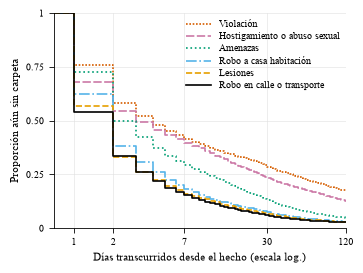

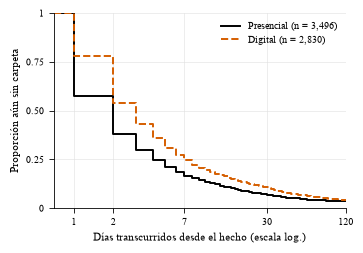

tipo_delito
Robo en calle o transporte      25279
Amenazas                        22680
Hostigamiento o abuso sexual     6875
Lesiones                         5748
Robo a casa habitación           4797
Violación                        2535


In [ ]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.size": 0,
    "pdf.fonttype": 42, "ps.fonttype": 42,     # fuentes incrustadas (requisito IEEE)
})
ANCHO, X_MIN, TICKS = 3.5, 0.7, [1, 2, 7, 30, 120]

# Paleta Okabe-Ito (segura para daltonismo) + estilos de línea distintos,
# para que se distingan también impresas en blanco y negro.
ESTILO_TIPO = {
    "Robo en calle o transporte":   ("#000000", "-"),
    "Lesiones":                     ("#E69F00", "--"),
    "Robo a casa habitación":       ("#56B4E9", "-."),
    "Amenazas":                     ("#009E73", ":"),
    "Hostigamiento o abuso sexual": ("#CC79A7", (0, (5, 1.5))),
    "Violación":                    ("#D55E00", (0, (1, 1))),
}

def curva_km(ax, datos, etiqueta, color, estilo, lw=1.2):
    """Kaplan-Meier con convención diaria: rezago r -> la curva cae en x = r + 1."""
    t  = np.minimum(datos["rezago"], TRUNC) + 1
    km = KaplanMeierFitter().fit(t, datos["evento"])
    S  = km.survival_function_.iloc[:, 0]
    x  = np.r_[X_MIN, S.index[1:].values]     # arranque visible en S = 1
    y  = np.r_[1.0,   S.values[1:]]
    ax.step(x, y, where="post", color=color, ls=estilo, lw=lw, label=etiqueta)

def formato_ejes(ax):
    ax.set_xscale("log"); ax.set_xlim(X_MIN, TRUNC); ax.set_ylim(0, 1)
    ax.set_xticks(TICKS); ax.set_xticklabels([str(t) for t in TICKS])
    ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(["0", "0.25", "0.50", "0.75", "1"])
    ax.set_xlabel("Días transcurridos desde el hecho (escala log.)")
    ax.set_ylabel("Proporción aún sin carpeta")
    ax.grid(True, which="major", lw=0.4, color="0.88"); ax.set_axisbelow(True)

# --- Figura 1: por tipo de delito ---
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
# Orden de la leyenda = orden de las curvas a los 30 días (de arriba abajo)
orden = (garant.groupby("tipo_delito", observed=True)["rezago"]
               .apply(lambda r: (r <= 30).mean()).sort_values().index)
for tipo in orden:
    color, estilo = ESTILO_TIPO[tipo]
    curva_km(ax, garant[garant["tipo_delito"] == tipo], tipo, color, estilo)
formato_ejes(ax)
ax.legend(frameon=False, loc="upper right", handlelength=2.6,
          labelspacing=0.3, borderaxespad=0.2)
fig.tight_layout(pad=0.3)
fig.savefig(RUTA_SALIDAS / "fig_supervivencia_tipo.pdf")
fig.savefig(RUTA_SALIDAS / "fig_supervivencia_tipo.png", dpi=600)
plt.show()

# --- Figura 2: por canal, robo en calle o transporte sin violencia ---
robo_sv = garant[(garant["tipo_delito"] == REF_TIPO) & (garant["con_violencia"] == 0)]
fig, ax = plt.subplots(figsize=(ANCHO, 2.4))
for canal, etq, color, estilo in [(0, "Presencial", "#000000", "-"),
                                  (1, "Digital",    "#D55E00", "--")]:
    sub = robo_sv[robo_sv["digital"] == canal]
    curva_km(ax, sub, f"{etq} (n = {len(sub):,})", color, estilo, lw=1.4)
formato_ejes(ax)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(pad=0.3)
fig.savefig(RUTA_SALIDAS / "fig_supervivencia_canal.pdf")
fig.savefig(RUTA_SALIDAS / "fig_supervivencia_canal.png", dpi=600)
plt.show()

# Tamaños de muestra para el pie de la figura 1
print(garant["tipo_delito"].value_counts().to_string())

**Fig. 1.** Proporción de hechos aún sin carpeta de investigación según días transcurridos, por tipo de delito. Estimador de Kaplan-Meier sobre hechos de enero a marzo de 2020–2024 (n = 67,914), con 120 días de observación completa. Intervalos de confianza al 95% omitidos por ser más estrechos que el grosor de línea.

**Fig. 2.** Igual que la Fig. 1, para robo en calle o transporte sin violencia, por canal de denuncia.

## Rezago de denuncia y truncamiento del registro

- **Datos y limpieza**. Se usó el extracto de carpetas de investigación de la FGJ-CDMX con corte al 31 de enero de 2025 (2,098,743 registros, 2016–2025). El 2.6% de las fechas venía con la hora anexa; al recuperar ese formato en lugar de descartarlo, se conservaron 53,555 carpetas iniciadas desde noviembre de 2024, que concentran los hechos con menor ventana de observación. Se descartaron 563 registros sin fecha y 110 con rezago negativo, y se marcaron 12,530 con rezago mayor a cinco años, de los cuales solo siete caen en el periodo de estudio. El universo del modelo (delitos del núcleo, hechos de 2020 a 2024, alcaldía identificada, sin hechos no delictivos ni incompetencias) suma 259,954 carpetas y reproduce el conteo C del resto del trabajo con una diferencia de una carpeta. El rezago se midió en días entre el hecho y el inicio de la carpeta; como el 36% vale cero, cada observación se trató como censurada en el intervalo [r, r+1).

- **Truncamiento**. Una carpeta solo se observa si se inició antes del corte, de modo que los hechos recientes pierden selectivamente sus denuncias tardías. El problema se abordó de dos formas. La versión por diseño restringe a hechos de enero a marzo y censura a 120 días, lo que iguala la ventana de todos los casos (n = 67,914). La versión completa usa todos los casos y maximiza una verosimilitud que divide la probabilidad de cada rezago entre F(w+1), la probabilidad de haber sido observado dada su ventana w.

- **Modelo y supuestos**. Se ajustó un modelo de tiempo de falla acelerado log-logístico, preferido sobre el log-normal por AIC (diferencia de 1,349), aunque ambos producen razones casi idénticas (r = 0.997). La gráfica de momios proporcionales mostró rectas paralelas para robos, amenazas y lesiones, pero pendientes más planas para los delitos sexuales, por lo que se permitió que el parámetro de forma variara por tipo de delito (ΔAIC = 1,645). La prueba de riesgos proporcionales no aplica a esta familia, y su supuesto equivalente, el de momios proporcionales, es el que se verificó. Los residuales de Cox-Snell siguen la recta de 45° en el cuerpo de la distribución, pero la cola observada es más pesada que la del modelo. Esto es atribuible a heterogeneidad no observada de las víctimas, cuyas características no contiene este registro.

- **Resultados**. Las razones de tiempo se interpretan como razones de medianas (Tabla I). Frente a un robo en calle o transporte, la mediana se multiplica por 4.2 en violación y por 2.9 en hostigamiento o abuso sexual, cuya distribución es además la más dispersa (β ≈ 0.53, frente a 0.88–1.02 en los demás tipos). Un robo con violencia llega a carpeta 31% antes. Denunciar por el canal digital casi duplica el tiempo (razón 1.98; IC 95%: 1.90–2.06). La Fig. 2 muestra que la diferencia se concentra en el primer día, lo que es consistente con un retraso administrativo del canal más que con la selección de denunciantes tardíos, aunque estos datos no permiten distinguir ambos mecanismos. Cuajimalpa (1.56) y Xochimilco (1.47) son las alcaldías más lentas. Ignorar el truncamiento produce justo el sesgo esperado: 2024 aparece casi tan rápido como 2020 (1.05, contra 1.13 corregido) y la razón de violación cae de 4.2 a 2.8. En el resto de los coeficientes las dos versiones coinciden (r = 0.985).

- **Conexión con el modelo de áreas pequeñas**. El análisis produce dos covariables administrativas por alcaldía y año: la proporción de carpetas iniciadas en siete días, estandarizada por tipo de delito, y la proporción de robos en calle denunciados en línea. Ambas se calcularon con un corte homologado de trece meses para que todos los años sean comparables. La mediana del rezago se descartó porque vale un día en 76 de las 80 celdas. Además, el análisis corrige el subconteo de C en 2024. El factor de completitud, obtenido con un estimador de Horvitz-Thompson sobre la distribución empírica de los rezagos de 2021–2022, es de 1.026 para la ciudad y varía entre 1.020 y 1.042 por alcaldía. La versión basada en el modelo, que subestima la cola, da 1.021 y funciona como cota inferior.